In [1]:
import os
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_in = os.path.join(pth, 'data', 'modeling', 'landscape')
pth_out = os.path.join(pth, 'figures', 'modeling')

In [3]:
# load & select data
adata = sc.read_h5ad(os.path.join(pth_in, 'development.h5ad'))
adata = adata[adata.obs.landscape == 'True'].copy()
adata = adata[~((adata.obs.source == 'GSE162534') &
                (adata.obs.latent_z < .5))].copy()
adata = adata[~((adata.obs.source == 'GSE229103') &
      (adata[:, 'Pou5f1'].X.toarray() == 0).flatten())].copy()
adata

AnnData object with n_obs × n_vars = 6271 × 856
    obs: 'Stages', 'Clusters', 'Type', 'LineageAnnotations', 'celltype', 'trajectory', 't', 'training', 'validation', 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'plates', 'devtime', 'location', 'total_counts_ERCC', 'pct_counts_ERCC', 'doublet_scores', 'CytoTRACE', 'Gut_neuron', 'Sensory', 'Symp', 'enFib', 'ChC', 'Gut_glia', 'NCC', 'Mesenchyme', 'Melanocytes', 'SatGlia', 'SC', 'BCC', 'conflict', 'assignments', 'Hub', 'Hub_leiden', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'batch', 'percent_mito', 'n_counts', 'bh_pval', 'region', 'tissue', 'adj_stage', 'adj_sample', 'S_score', 'G2M_score', 'phase', 'leiden_R', 'celltype_original', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'source', 'weight_celltype', 'weight_source', 'weight', 'latent_z', 'Early', 'Late', 'X_mesen1', 'X

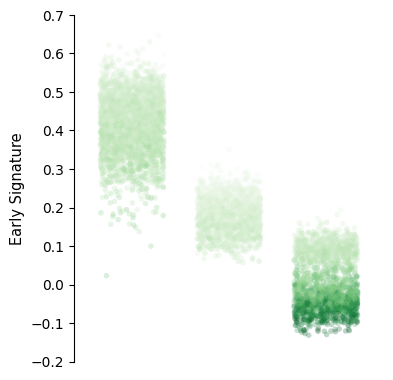

In [14]:
# module stripplot -> dendrogram
fig, ax = plt.subplots(1, 1, figsize = (4, 4.5))
sns.stripplot(data = adata.obs,
              x = 'source',
              y = 'Early',
              hue = 'Late',
              palette = 'Greens',
              s = 4, alpha = .25,
              jitter = .33,
              legend = False,
              ax = ax)

ax.set_xticks([]); ax.set_xlabel('')
xlim = ax.get_xlim()
ax.set_xlim(xlim[0] - .1, xlim[1] + .1)
ax.set_ylim(-.2, .7)
ax.set_ylabel('Early Signature', size = 10.5)
for sp in ('top', 'right', 'bottom'):
    ax.spines[sp].set_visible(False)

fn = os.path.join(pth_out, 'evolution.pdf')
plt.savefig(fn, bbox_inches = 'tight')